<a href="https://colab.research.google.com/github/Ana-shritaaaa/Simulations/blob/main/Google%20Colab%20Projects/Monty_Hall_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

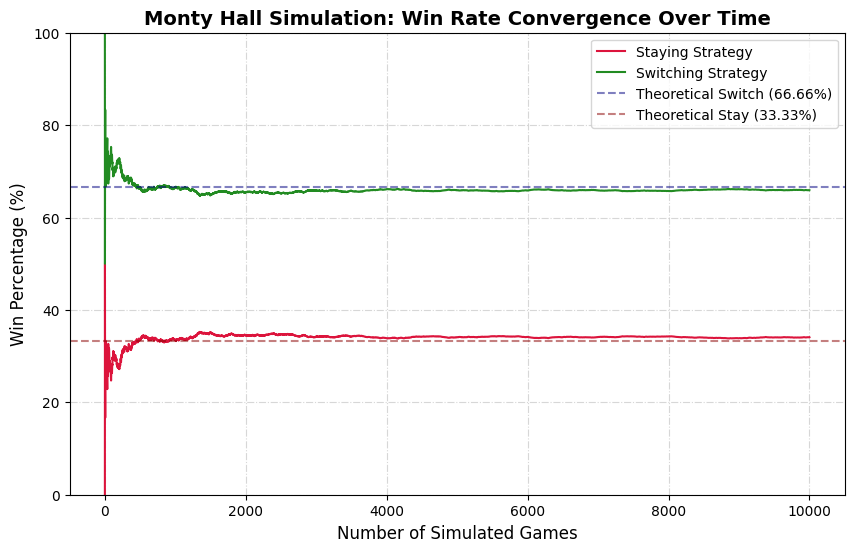

In [ ]:
import matplotlib.pyplot as plt #imported matplotlib, a library used to plot graphs
import random #imported random, a random variable generator

def simulate_monty_hall(num_games=10000):  #defined a function simulate_monty_hall on the variable num_games. 10,000 games shall be simulated here
#variable defining done below:
  stay_wins = 0   #number of wins if player stays
  switch_wins = 0  #number of wins if player switches
  doors = [0, 1, 2]  #door options 0, 1 and 2
  game_numbers = []  #number of games played so far
  stay_percentages = []   #percentage of wins when player stays
  switch_percentages = []   #percentage of wins when player switches

  for game in range(num_games):    #for every game played, ranging from the first (0)th game to the last (10,000)th game)
    #pick a random door among the 3 to be the car door
    car_door = random.choice(doors)
    #pick a random door among the 3 to be chosen by the player
    pick_door = random.choice(doors)
    #Monty opens a door
    monty_door = random.choice([door for door in doors if door != pick_door and door != car_door]) # this door must be from our list doors i.e. among the 3 doors, such that it does not contain the car, and it isn't the door picked by the player
    #conditions for winning door defined below:
    if pick_door == car_door:
      stay_wins += 1
    else:
      switch_wins += 1

    current_game_count = game + 1   #this is done because say you played one game. that game is the 0th game. when finding the switch percentages and stay percentages, you shall be dividing by number of games so far played. when dividing by 0, an error will show. to prevent this, +1 is done to index all games starting from 1 instead of 0
    game_numbers.append(current_game_count) #adding count of games played
    stay_percentages.append((stay_wins / current_game_count) * 100) #calculating stay win percentage so far
    switch_percentages.append((switch_wins / current_game_count) * 100)#calculating switch win percentage so far

  return game_numbers, stay_percentages, switch_percentages #values returned as output

# Run the simulation
game_numbers, stay_percentages, switch_percentages = simulate_monty_hall(num_games=10000)  #simulation run, and results saved in variables outside the function, so that the plotting process can receive it

#plots results
plt.figure(figsize=(10, 6))#makes a blank graph of 10 inches x 6 inches

#plots of simulated results
plt.plot(game_numbers, stay_percentages, label="Staying Strategy", color="crimson", linewidth=1.5) #plots a line with (game_number, stay_percentage) coordinates, for every game played
plt.plot(game_numbers, switch_percentages, label="Switching Strategy", color="forestgreen", linewidth=1.5) #plots a line with (game_number, switch_percentage) coordinates, for every game played

#plots of expected results
plt.axhline(y=66.66, color="navy", linestyle="--", alpha=0.5, label="Theoretical Switch (66.66%)") #plots a reference horizontal line at y=66.66, as all y values (switch percentages) are expected to converge there over time
plt.axhline(y=33.33, color="darkred", linestyle="--", alpha=0.5, label="Theoretical Stay (33.33%)") #plots a reference horizontal line at y=33.33, as all y values(stay percentages) are expected to converge there over time

#aesthetics and neatness
plt.title("Monty Hall Simulation: Win Rate Convergence Over Time", fontsize=14, fontweight='bold') #title of the graph
plt.xlabel("Number of Simulated Games", fontsize=12) #x axis label
plt.ylabel("Win Percentage (%)", fontsize=12) #y axis label
plt.ylim(0, 100) #limits y values from 0 to 100, as they are percentages
plt.grid(True, linestyle='-.', alpha=0.5) #grid true means grid lines are appearing in the background as dotted lines with 50% transparency
plt.legend(loc="upper right") #legend is locked to the upper right corner

plt.show() #shows graph